11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Round: 1 Accuracy: 0.8836 Loss: 0.4033
Round: 2 Accuracy: 0.9047 Loss: 0.3108
Round: 3 Accuracy: 0.9185 Loss: 0.2631
Round: 4 Accuracy: 0.926 Loss: 0.2357
Round: 5 Accuracy: 0.9354 Loss: 0.2111

Final Test Accuracy: 0.9354
Final Test Loss: 0.2111


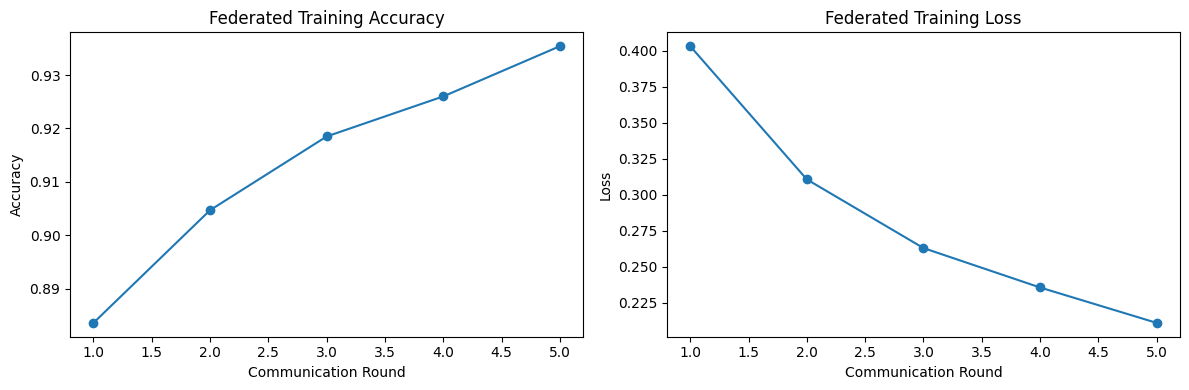

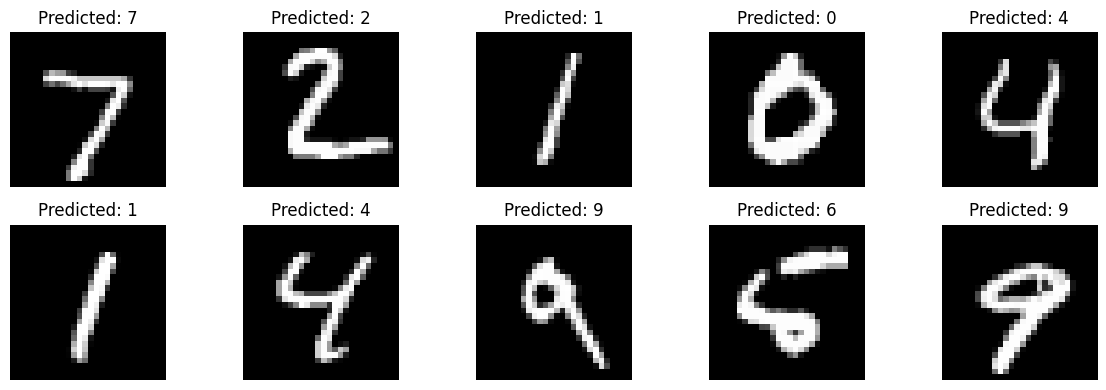

In [2]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
tf.random.set_seed(42)

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

x_train = x_train[:10000].astype("float32") / 255.0
y_train = y_train[:10000]
x_test = x_test.astype("float32") / 255.0

x_train = x_train[..., np.newaxis]
x_test = x_test[..., np.newaxis]

num_clients = 5
client_data = []
indices = np.random.permutation(len(x_train))

for i in range(num_clients):
    idx = indices[i * 2000:(i + 1) * 2000]
    client_data.append((x_train[idx], y_train[idx]))

def create_model():
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28, 28, 1)),
        tf.keras.layers.Conv2D(16, (3, 3), activation="relu"),
        tf.keras.layers.MaxPooling2D((2, 2)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dense(10, activation="softmax")])
    model.compile(
        optimizer=tf.keras.optimizers.SGD(learning_rate=0.02, momentum=0.9),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"])
    return model

global_model = create_model()
accuracy_history = []
loss_history = []

for round_num in range(1, 6):
    client_weights = []
    client_sizes = []

    global_weights = global_model.get_weights()

    for x_client, y_client in client_data:
        local_model = create_model()
        local_model.set_weights(global_weights)

        local_model.fit(
            x_client, y_client,
            epochs=1,
            batch_size=32,
            verbose=0)

        client_weights.append(local_model.get_weights())
        client_sizes.append(len(x_client))

    total_samples = sum(client_sizes)

    averaged_weights = [
        np.average(
            [client_weights[i][layer] for i in range(num_clients)],
            axis=0,
            weights=client_sizes)for layer in range(len(global_weights))]

    global_model.set_weights(averaged_weights)
    loss, accuracy = global_model.evaluate(x_test, y_test, verbose=0)
    accuracy_history.append(accuracy)
    loss_history.append(loss)
    print("Round:", round_num,
          "Accuracy:", round(accuracy, 4),
          "Loss:", round(loss, 4))

test_loss, test_accuracy = global_model.evaluate(x_test, y_test, verbose=0)
print("\nFinal Test Accuracy:", round(test_accuracy, 4))
print("Final Test Loss:", round(test_loss, 4))

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(range(1, 6), accuracy_history, marker="o")
plt.title("Federated Training Accuracy")
plt.xlabel("Communication Round")
plt.ylabel("Accuracy")
plt.subplot(1, 2, 2)
plt.plot(range(1, 6), loss_history, marker="o")
plt.title("Federated Training Loss")
plt.xlabel("Communication Round")
plt.ylabel("Loss")
plt.tight_layout()
plt.show()
predictions = global_model.predict(x_test[:10], verbose=0)
plt.figure(figsize=(12, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i].squeeze(), cmap="gray")
    plt.title("Predicted: " + str(np.argmax(predictions[i])))
    plt.axis("off")
plt.tight_layout()
plt.show()